In [547]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [548]:

df = pd.read_csv("lab_ticket_resolution.csv")

In [549]:

print(df.shape)      #Number of rows and columns
print(df.dtypes)     #Data type of each column
print(df.describe(include="all"))     #Descriptive statistics
print(df.isna().sum())         #Number of missing values in each column
print(df.head())        #First five rows

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [550]:

# Target variable
y = df["resolution_hours"]

# Input features
X = df.drop(columns=[
    "ticket_id",
    "reopened",
    "lines_changed",
    "resolution_hours"
])

print("Input features:")
print(X.head())

print("\nTarget:")
print(y.head())


Input features:
   complexity_score  team_experience_years
0                 6                    5.6
1                 9                   11.5
2                 6                    3.3
3                 5                    9.6
4                 3                    6.4

Target:
0    24.77
1    33.43
2    17.82
3    19.54
4    11.04
Name: resolution_hours, dtype: float64



### Select Features and Target

The target variable (y) is `resolution_hours` because we want to predict how long a support ticket takes to resolve.

I selected two input features:
- `complexity_score`
- `team_experience_years`

I excluded:
- `ticket_id` because it is only an identifier.
- `reopened` because it may not be known before the ticket is resolved.
- `lines_changed` because it may not be known before fixing the ticket.
- `resolution_hours` because it is the target we want to predict.

These features were selected to avoid data leakage.


In [551]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (192, 2)
Testing: (48, 2)



### Task 3: Split the Dataset

I divided the dataset into two parts:

- 80% training data to teach the models.
- 20% testing data to check their predictions.

I used `random_state=42` to get the same split each time.

In [552]:

# Create baseline model
dummy_model = DummyRegressor(strategy="mean")

# Train the model
dummy_model.fit(X_train, y_train)

# Predict test data
dummy_predictions = dummy_model.predict(X_test)

# Calculate errors
dummy_mae = mean_absolute_error(y_test, dummy_predictions)
dummy_rmse = np.sqrt(mean_squared_error(y_test, dummy_predictions))
dummy_r2 = r2_score(y_test, dummy_predictions)

# Display results
print("Baseline MAE:", dummy_mae)
print("Baseline RMSE:", dummy_rmse)
print("Baseline R²:", dummy_r2)


Baseline MAE: 9.113951822916667
Baseline RMSE: 10.597684800766308
Baseline R²: -0.021016765260001957



### Task 4: Mean Baseline Model

I used DummyRegressor with the mean strategy.
This model predicts the average resolution time for every ticket.
It does not use the input features to make different predictions.

I calculated MAE, RMSE, and R² to measure the model's performance.

This model will be used as a starting point to compare with other models.


In [553]:

# Create Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Make predictions
linear_predictions = linear_model.predict(X_test)

# Calculate errors
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

# Display results
print("Linear MAE:", linear_mae)
print("Linear RMSE:", linear_rmse)
print("Linear R²:", linear_r2)


Linear MAE: 2.9060129859502593
Linear RMSE: 3.572274354879709
Linear R²: 0.8839886480141969



### Task 5: Linear Regression

I trained a Linear Regression model using complexity_score and team_experience_years.

The model learns how these features are related to resolution time.

I used the training data to train the model and the test data to check its predictions.

I calculated MAE, RMSE, and R² to evaluate its performance.


In [554]:

# Create cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Polynomial degree 2
poly2_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

# Polynomial degree 3
poly3_model = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

# Cross-validation scores
poly2_scores = cross_val_score(
    poly2_model, X_train, y_train,
    cv=cv, scoring="neg_mean_absolute_error"
)

poly3_scores = cross_val_score(
    poly3_model, X_train, y_train,
    cv=cv, scoring="neg_mean_absolute_error"
)

print("Degree 2 CV MAE:", -poly2_scores.mean())
print("Degree 3 CV MAE:", -poly3_scores.mean())


Degree 2 CV MAE: 3.131261273764686
Degree 3 CV MAE: 3.1620030669380585


In [555]:

# Train both models
poly2_model.fit(X_train, y_train)
poly3_model.fit(X_train, y_train)

# Make predictions
poly2_predictions = poly2_model.predict(X_test)
poly3_predictions = poly3_model.predict(X_test)

# Degree 2 results
print("Polynomial Degree 2")
print("MAE:", mean_absolute_error(y_test, poly2_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, poly2_predictions)))
print("R²:", r2_score(y_test, poly2_predictions))

# Degree 3 results
print("\nPolynomial Degree 3")
print("MAE:", mean_absolute_error(y_test, poly3_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, poly3_predictions)))
print("R²:", r2_score(y_test, poly3_predictions))


Polynomial Degree 2
MAE: 3.0202226065182844
RMSE: 3.740909639943716
R²: 0.8727770936373884

Polynomial Degree 3
MAE: 3.13975234781026
RMSE: 3.948873016354166
R²: 0.8582388547303954



### Task 6: Polynomial Regression

I trained two Polynomial Regression models with degrees 2 and 3.

Polynomial Regression can learn more complex relationships between the features and resolution time.

I used 5-fold cross-validation to compare the two models using the training data.

I also calculated MAE, RMSE, and R² on the test data.

The model with the lower validation MAE performed better during cross-validation.


In [556]:

from sklearn.model_selection import GridSearchCV

In [557]:
# Create Ridge pipeline
ridge_pipeline = make_pipeline(
    StandardScaler(),
    Ridge()
)

# Find the best alpha
ridge_search = GridSearchCV(
    ridge_pipeline,
    {"ridge__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=cv,
    scoring="neg_mean_absolute_error"
)

# Train model
ridge_search.fit(X_train, y_train)

# Get best model
ridge_model = ridge_search.best_estimator_

# Make predictions
ridge_predictions = ridge_model.predict(X_test)

# Display results
print("Best Ridge alpha:", ridge_search.best_params_)
print("Best CV MAE:", -ridge_search.best_score_)
print("Test MAE:", mean_absolute_error(y_test, ridge_predictions))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, ridge_predictions)))
print("Test R²:", r2_score(y_test, ridge_predictions))

Best Ridge alpha: {'ridge__alpha': 0.01}
Best CV MAE: 3.168179510394689
Test MAE: 2.9060051099890867
Test RMSE: 3.572253043929423
Test R²: 0.8839900321770773



### Task 7.1: Ridge Regression

I trained a Ridge Regression model using StandardScaler.

Ridge uses regularization to reduce large coefficients.

I used GridSearchCV to find the best alpha value using cross-validation.

I evaluated the model using MAE, RMSE, and R².

In [558]:

# Create Lasso pipeline
lasso_pipeline = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=10000)
)

# Find the best alpha
lasso_search = GridSearchCV(
    lasso_pipeline,
    {"lasso__alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=cv,
    scoring="neg_mean_absolute_error"
)

# Train model
lasso_search.fit(X_train, y_train)

# Get best model
lasso_model = lasso_search.best_estimator_

# Make predictions
lasso_predictions = lasso_model.predict(X_test)

# Display results
print("Best Lasso alpha:", lasso_search.best_params_)
print("Best CV MAE:", -lasso_search.best_score_)
print("Test MAE:", mean_absolute_error(y_test, lasso_predictions))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, lasso_predictions)))
print("Test R²:", r2_score(y_test, lasso_predictions))


Best Lasso alpha: {'lasso__alpha': 0.001}
Best CV MAE: 3.1682419077442643
Test MAE: 2.9061249077410434
Test RMSE: 3.572287300493528
Test R²: 0.8839878071824279



### Task 7.2: Lasso Regression

I trained a Lasso Regression model using StandardScaler.

Lasso uses regularization to reduce coefficients and can make some coefficients zero.

I used GridSearchCV to select the best alpha value.

I evaluated the model using MAE, RMSE, and R².


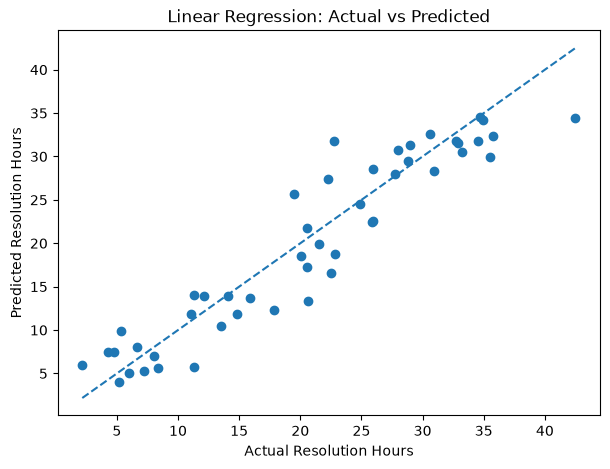

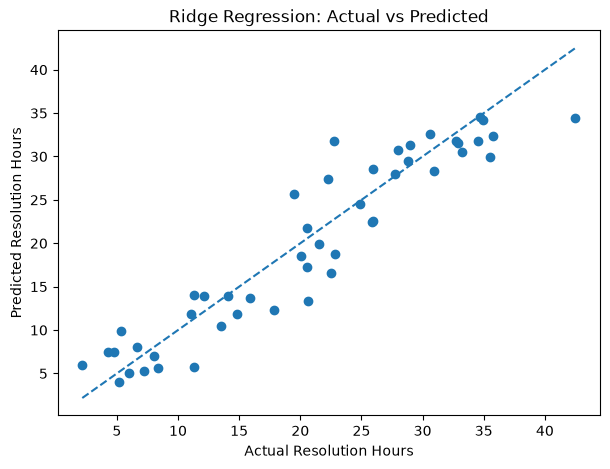

In [559]:

import matplotlib.pyplot as plt

# Compare two models
models_to_plot = [
    ("Linear Regression", linear_predictions),
    ("Ridge Regression", ridge_predictions)
]

for name, predictions in models_to_plot:
    plt.figure(figsize=(7, 5))

    # Actual vs predicted values
    plt.scatter(y_test, predictions)

    # Perfect prediction line
    minimum = min(y_test.min(), predictions.min())
    maximum = max(y_test.max(), predictions.max())

    plt.plot(
        [minimum, maximum],
        [minimum, maximum],
        linestyle="--"
    )

    plt.xlabel("Actual Resolution Hours")
    plt.ylabel("Predicted Resolution Hours")
    plt.title(name + ": Actual vs Predicted")

    plt.show()


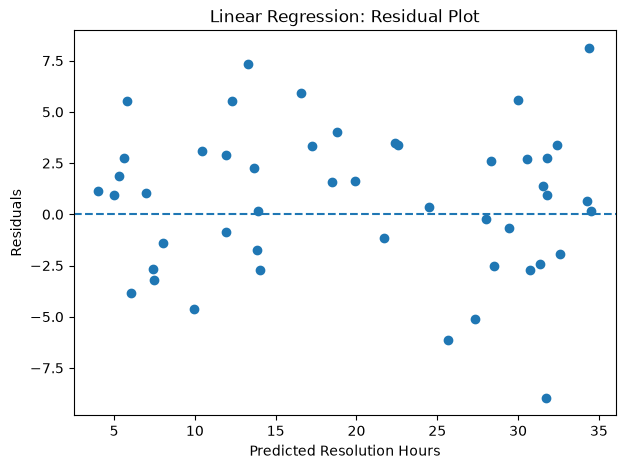

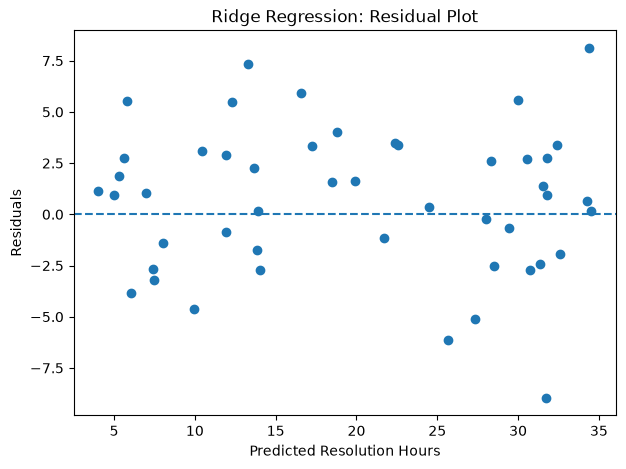

In [560]:

for name, predictions in models_to_plot:
    # Calculate residuals
    residuals = y_test - predictions

    plt.figure(figsize=(7, 5))

    plt.scatter(predictions, residuals)
    plt.axhline(y=0, linestyle="--")

    plt.xlabel("Predicted Resolution Hours")
    plt.ylabel("Residuals")
    plt.title(name + ": Residual Plot")

    plt.show()


### 1. Actual vs Predicted Plots

I created Actual vs Predicted plots for Linear Regression and Ridge Regression.

In both graphs, most points are close to the diagonal line. This means the models predict resolution time reasonably well.

Some points are far from the line, which means the models made larger prediction errors for those tickets.

Both models show very similar results.

### 2. Residual Plots

I created residual plots for Linear Regression and Ridge Regression.

The residuals are scattered above and below the zero line.

There is no clear curved pattern in the plots. However, some points have large positive or negative residuals.

The residuals range approximately from -9 to +8 hours.

This means the models predict many tickets reasonably well, but they make larger errors for some tickets.

#### Therefore

Linear Regression and Ridge Regression show similar prediction performance.

Most predictions are close to the actual resolution hours, but some errors are large.

The residual plots do not show a clear curved pattern, so a simple linear model may be suitable for this dataset.

More testing is needed before using the models in a real organization.


In [561]:

# Store model names and predictions
models = [
    ("Mean Baseline", dummy_predictions),
    ("Linear Regression", linear_predictions),
    ("Polynomial Degree 2", poly2_predictions),
    ("Polynomial Degree 3", poly3_predictions),
    ("Ridge Regression", ridge_predictions),
    ("Lasso Regression", lasso_predictions)
]

# Create an empty list
results = []

# Calculate metrics for each model
for name, predictions in models:
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

# Create a table
results_df = pd.DataFrame(results)

# Display the table
print(results_df.round(3))


                 Model    MAE    RMSE     R²
0        Mean Baseline  9.114  10.598 -0.021
1    Linear Regression  2.906   3.572  0.884
2  Polynomial Degree 2  3.020   3.741  0.873
3  Polynomial Degree 3  3.140   3.949  0.858
4     Ridge Regression  2.906   3.572  0.884
5     Lasso Regression  2.906   3.572  0.884



### Task 9: Model Comparison

I compared six regression models using MAE, RMSE, and R².

- MAE shows the average prediction error.
- RMSE gives more importance to large prediction errors.
- R² shows how well the model explains the differences in resolution time.

A model with lower MAE and RMSE and higher R² generally performs better.

I will use these results to choose a suitable model for predicting ticket resolution time.


In [562]:

# Find model with lowest MAE
best_model = results_df.loc[results_df["MAE"].idxmin()]

print("Best model:", best_model["Model"])
print("MAE:", round(best_model["MAE"], 3))
print("RMSE:", round(best_model["RMSE"], 3))
print("R²:", round(best_model["R²"], 3))


Best model: Ridge Regression
MAE: 2.906
RMSE: 3.572
R²: 0.884



### Task 9: Final Model Recommendation

I compared six regression models using MAE, RMSE, and R².

Ridge Regression was selected as the best model based on the lowest MAE.

It achieved:
- MAE = 2.906 hours
- RMSE = 3.572 hours
- R² = 0.884

Linear Regression and Lasso Regression also gave almost the same results.

Polynomial Regression did not improve prediction accuracy.

I recommend Ridge Regression because it performed well and uses regularization to control large coefficients.

However, the dataset is synthetic. Before using the model in a real organization, I would test it with real support tickets and check its performance on new data.
